**Looped transformers series:** [01 Universal Transformer](01_universal_transformer.ipynb) · **02 Adaptive Computation Time** · [03 Recurrent depth](03_recurrent_depth.ipynb) · [04 Fixed point (DEQ)](04_deq_fixed_point.ipynb) · [05 Mixture-of-Recursions](05_mixture_of_recursions.ipynb) · [06 Relaxed recursion](06_relaxed_recursion.ipynb) · [07 Scratchpad memory](07_scratchpad_memory.ipynb) · [08 Layer-sharing schedules](08_layer_sharing.ipynb)

# Looped transformers 02 - Adaptive Computation Time: let each token decide when to stop

A *looped* transformer applies **one** shared block again and again, so depth becomes a knob you can turn at run time instead of a fixed architecture choice. Notebook 01 always used the same number of passes for every token. **Adaptive Computation Time (ACT, Graves 2016)** adds a tiny *halting unit* that lets **each token decide for itself how many passes it needs**: easy tokens can stop after one or two passes, hard ones can keep thinking. In this notebook we build ACT from scratch in pure PyTorch, check every formula by hand on numbers we choose, see exactly which parts of ACT receive gradient, train it on a toy corpus and on real English text (Python docstrings), and then measure honestly whether it actually spends more compute on harder characters.

| What you will learn | Where |
|---|---|
| The looped block recap: one block + a step embedding | §1, §3 |
| The ACT equations: halting probability, cumulative mass, remainder $R$, passes $N$, ponder cost | §2 |
| ACT bookkeeping on a hand-made example, verified by `assert` | §3 |
| Why $R$ carries gradient and $N$ does not (shown with autograd) | §3 |
| Halted tokens: still transformed (others attend to them), but their output is frozen | §3, §4 |
| Training loop, per-character pass heatmaps, per-pass cumulative halting | §6, §7 |
| Experiments: the ponder weight $\tau$ trade-off, halting-bias init, "does ACT think longer on hard characters?" | §8 |

**Prerequisites:** Python, basic PyTorch (tensors, `nn.Module`, autograd, an optimizer loop), a rough idea of what attention is. Notebook 01 helps but is not required.

**Estimated runtime:** about 6.5 minutes on an idle laptop CPU with 2 threads, and up to ~11 minutes when other jobs share the machine (the exact time is printed in the last cell).

## 0. Setup

Only the standard library, `torch`, `numpy` and `matplotlib`. We pin the number of CPU threads (other jobs may share the machine) and fix all seeds so the numbers below are reproducible.

In [1]:
import math
import random
import time

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

torch.set_num_threads(2)
NOTEBOOK_START = time.time()


def set_seed(seed: int) -> None:
    """Fix every random number generator we use."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


set_seed(0)
print("torch", torch.__version__, "| threads", torch.get_num_threads())

torch 2.13.0 | threads 2


## 1. Intuition

**Analogy.** Picture a group of students reading a sentence together, one word each. A teacher says "read your word again and think" over and over. After each round every student raises a hand a little: "I am 40% sure I am done", "I am 99% sure". When a student's raised-hand total reaches 100%, they **stop writing their answer** - but they stay in the room and keep talking, because their neighbours may still need to ask them questions. The final answer of each student is a weighted average of what they had written after each round, weighted by how much "done-ness" they reported in that round. And the teacher charges a small fee per round, so nobody thinks longer than necessary.

In transformer terms:
* the **students** are token positions,
* a **round** is one pass of the shared transformer block,
* the **raised hand** is the halting probability $p_t^i$ produced by a single linear layer + sigmoid,
* **staying in the room** = halted tokens are still transformed so that other tokens can attend to them, but their output stops changing,
* the **fee** is the *ponder cost* $\tau \cdot \text{mean}(N + R)$ added to the loss.

```mermaid
flowchart TD
    X["tokens x (B, L)"] --> E["token + position embedding<br/>h_0 (B, L, d)"]
    E --> S["add step embedding e_t"]
    S --> BLK["shared transformer block<br/>(same weights every pass)"]
    BLK --> H["state h_t (B, L, d)"]
    H --> P["halting unit<br/>p_t = sigmoid(w·h_t + b)  (B, L)"]
    P --> ACC{"for each token:<br/>cum + p_t >= 1 - eps ?"}
    ACC -- "no: weight = p_t, keep going" --> S
    ACC -- "yes (or t = T_max): weight = R, freeze output" --> Y
    H -. "weighted by lambda_t" .-> Y["output y = sum_t lambda_t h_t"]
    Y --> HEAD["LayerNorm + linear head<br/>logits (B, L, V)"]
    ACC --> PC["ponder cost: tau · mean(N + R)"]
```

The loop back-edge is the key picture: **the same block weights are reused on every pass**, and the halting unit decides, per token, which pass is its last.

## 2. The math

Shapes: batch $B$, sequence length $L$, model width $d$, vocabulary $V$, maximum number of passes $T_{\max}$. Index $i$ runs over the $B \cdot L$ token positions; $t = 1, \dots, T_{\max}$ is the pass number.

**Looped block (recap).** Starting from the embeddings $h_0 \in \mathbb{R}^{B \times L \times d}$,

$$h_t = \mathrm{Block}\big(h_{t-1} + e_t\big), \qquad t = 1, \dots, T_{\max}$$

where $\mathrm{Block}$ is one pre-norm transformer block whose weights are **shared across all passes**, and $e_t \in \mathbb{R}^{d}$ is a learned *step embedding* that tells the block which pass it is on.

**Halting unit.** A single linear map $w \in \mathbb{R}^{d}$, $b \in \mathbb{R}$ turns each token's state into a probability:

$$p_t^i = \sigma\!\left(w^\top h_t^i + b\right) \in (0, 1), \qquad p_t \in \mathbb{R}^{B \times L}.$$

**Halting rule.** Token $i$ halts at the first pass where its cumulative halting mass crosses $1 - \varepsilon$ ($\varepsilon$ is a small constant, here 0.01, so that a token can halt after one pass if $p_1^i \ge 0.99$):

$$N(i) = \min\Big\{\, n \le T_{\max} : \sum_{t=1}^{n} p_t^i \ge 1 - \varepsilon \Big\} \quad (\text{or } T_{\max} \text{ if never reached}).$$

$N(i)$ is an **integer**: the number of passes token $i$ uses.

**Remainder.** The last pass gets whatever probability mass is left so that the weights sum to exactly 1:

$$R(i) = 1 - \sum_{t=1}^{N(i)-1} p_t^i .$$

**Halting weights and output.**

$$\lambda_t^i = \begin{cases} p_t^i & t < N(i) \\ R(i) & t = N(i) \\ 0 & t > N(i) \end{cases} \qquad\Rightarrow\qquad \sum_t \lambda_t^i = 1, \qquad y^i = \sum_{t=1}^{T_{\max}} \lambda_t^i \, h_t^i \in \mathbb{R}^{d}.$$

$y \in \mathbb{R}^{B \times L \times d}$ then goes through a final LayerNorm and the output head to give logits $\in \mathbb{R}^{B \times L \times V}$.

**Ponder cost and total loss.**

$$\rho^i = N(i) + R(i), \qquad \mathcal{L} = \underbrace{\mathrm{CE}(\text{logits}, \text{targets})}_{\text{next-character loss}} + \tau \cdot \frac{1}{BL}\sum_i \rho^i .$$

$\tau \ge 0$ is the *time penalty*: how much one extra pass is worth in nats of cross-entropy.

**Which parts carry gradient?** $N(i)$ is a step function of the $p$'s (an `argmin` over a threshold test) - its derivative is zero almost everywhere, so it contributes **nothing** to the gradient. $R(i)$ is a smooth function of $p_1^i, \dots, p_{N-1}^i$, with $\partial \rho^i / \partial p_t^i = -1$ for $t < N(i)$. So the only thing the ponder cost can "say" to the network is **"make your earlier halting probabilities larger"**, which, once they get large enough, makes the token halt one pass earlier. Note also that $p_{N(i)}^i$ - the probability on the halting pass itself - receives no gradient from anything (it is replaced by $R$).

## 3. Building blocks from scratch

### 3.1 The shared transformer block

The series baseline: pre-norm block = LayerNorm → causal multi-head self-attention → residual, LayerNorm → MLP(GELU) → residual.

**The causal mask.** `nn.MultiheadAttention` takes a boolean `attn_mask` of shape `(L, L)` where `True` means "this query may NOT look at this key". For next-character prediction, position $i$ must only see positions $\le i$, so we put `True` strictly above the diagonal.

In [2]:
def causal_mask(length: int) -> torch.Tensor:
    """Boolean (L, L) mask; True above the diagonal = 'query i may not attend to key j > i'."""
    return torch.triu(torch.ones(length, length, dtype=torch.bool), diagonal=1)


class Block(nn.Module):
    """Pre-norm transformer block: x + Attn(LN(x)), then x + MLP(LN(x))."""

    def __init__(self, d_model: int, n_heads: int, mlp_mult: int = 4) -> None:
        super().__init__()
        self.ln1 = nn.LayerNorm(d_model)
        self.attn = nn.MultiheadAttention(d_model, n_heads, batch_first=True)
        self.ln2 = nn.LayerNorm(d_model)
        self.mlp = nn.Sequential(
            nn.Linear(d_model, mlp_mult * d_model),
            nn.GELU(),
            nn.Linear(mlp_mult * d_model, d_model),
        )

    def forward(self, x: torch.Tensor, mask: torch.Tensor) -> torch.Tensor:
        a = self.ln1(x)
        attn_out, _ = self.attn(a, a, a, attn_mask=mask, need_weights=False)
        x = x + attn_out
        x = x + self.mlp(self.ln2(x))
        return x


print(causal_mask(5).int())

tensor([[0, 1, 1, 1, 1],
        [0, 0, 1, 1, 1],
        [0, 0, 0, 1, 1],
        [0, 0, 0, 0, 1],
        [0, 0, 0, 0, 0]], dtype=torch.int32)


In [3]:
# Run the block on a toy tensor and check shapes + causality (changing a future token must not change the past).
set_seed(0)
toy_block = Block(d_model=16, n_heads=4)
x = torch.randn(2, 7, 16)
y = toy_block(x, causal_mask(7))
print("in", tuple(x.shape), "-> out", tuple(y.shape))
assert y.shape == x.shape

x_changed = x.clone()
x_changed[:, 5] += 10.0  # perturb position 5
y_changed = toy_block(x_changed, causal_mask(7))
assert torch.allclose(y[:, :5], y_changed[:, :5], atol=1e-6), "future token leaked into the past!"
assert not torch.allclose(y[:, 5:], y_changed[:, 5:]), "position 5 itself should change"
print("causality OK: positions 0-4 unchanged after perturbing position 5")

in (2, 7, 16) -> out (2, 7, 16)
causality OK: positions 0-4 unchanged after perturbing position 5


### 3.2 The looped block with a step embedding

Looping is just a `for` loop over the **same** module. The step embedding $e_t$ is a row of an `nn.Embedding(T_max, d)` added before each pass, so the block can behave slightly differently on pass 1 and pass 5 while still sharing all of its weights.

In [4]:
set_seed(0)
T_demo = 4
step_emb_demo = nn.Embedding(T_demo, 16)
h = x.clone()
for t in range(T_demo):
    h = toy_block(h + step_emb_demo.weight[t], causal_mask(7))  # same weights every pass
    print(f"pass {t + 1}: state shape {tuple(h.shape)}, mean |h| = {h.abs().mean():.3f}")
n_block = sum(p.numel() for p in toy_block.parameters())
print(f"parameters in the block: {n_block} (used {T_demo} times -> {T_demo}x compute, 1x parameters)")

pass 1: state shape (2, 7, 16), mean |h| = 1.088
pass 2: state shape (2, 7, 16), mean |h| = 1.599
pass 3: state shape (2, 7, 16), mean |h| = 1.964
pass 4: state shape (2, 7, 16), mean |h| = 2.310
parameters in the block: 3280 (used 4 times -> 4x compute, 1x parameters)


### 3.3 ACT bookkeeping on a hand-made example

Before putting ACT inside a network, let us run the bookkeeping on numbers **we choose**, so every result can be checked by hand. Three tokens, $T_{\max} = 4$, $\varepsilon = 0.01$, and the "states" are just the scalars $h_t = t$ (pass 1 → 1.0, pass 2 → 2.0, ...), so the output $y = \sum_t \lambda_t h_t$ is easy to compute mentally.

| token | $p_1, p_2, p_3, p_4$ | what should happen |
|---|---|---|
| A | 0.2, 0.5, 0.4, 0.9 | cum: 0.2, 0.7, then 0.7+0.4 = 1.1 ≥ 0.99 → halts at pass 3; $R = 1 - 0.7 = 0.3$; $\lambda = (0.2, 0.5, 0.3, 0)$; $y = 0.2 + 1.0 + 0.9 = 2.1$ |
| B | 0.995, 0.3, 0.3, 0.3 | 0.995 ≥ 0.99 → halts at pass 1; $R = 1$; $\lambda = (1, 0, 0, 0)$; $y = 1.0$ |
| C | 0.1, 0.1, 0.1, 0.1 | never reaches 0.99 → forced to halt at $T_{\max} = 4$; $R = 1 - 0.3 = 0.7$; $\lambda = (0.1, 0.1, 0.1, 0.7)$; $y = 0.1 + 0.2 + 0.3 + 2.8 = 3.4$ |

The function below is the **incremental** version - exactly the loop the model will run, one pass at a time.

In [5]:
def act_step(
    p: torch.Tensor, cum: torch.Tensor, running: torch.Tensor, is_last_pass: bool, eps: float
) -> tuple:
    """One pass of ACT bookkeeping for every token at once.

    p        : halting probability of this pass, any shape S
    cum      : sum of p over earlier passes (only for still-running tokens), shape S
    running  : bool, True if the token has not halted yet, shape S
    returns  : (weight lambda_t, halts_now, new cum, new running, remainder for the tokens halting now)
    """
    zeros = torch.zeros_like(p)
    halts_now = running & ((cum + p >= 1.0 - eps) | is_last_pass)  # crossing the threshold, or out of passes
    continues = running & ~halts_now
    remainder = 1.0 - cum                                          # R = 1 - sum of the earlier p's
    weight = torch.where(halts_now, remainder, torch.where(continues, p, zeros))  # lambda_t (0 once halted)
    new_cum = cum + torch.where(continues, p, zeros)
    return weight, halts_now, new_cum, continues, remainder


def run_act_bookkeeping(p_all: torch.Tensor, states: torch.Tensor, eps: float = 0.01) -> dict:
    """Apply act_step for t = 1..T. p_all: (T, n_tokens), states: (T, n_tokens)."""
    T, n = p_all.shape
    cum = torch.zeros(n)
    running = torch.ones(n, dtype=torch.bool)
    y = torch.zeros(n)
    N = torch.zeros(n)
    R = torch.zeros(n)
    weights = []
    for t in range(T):
        w, halts_now, cum, running, rem = act_step(p_all[t], cum, running, t == T - 1, eps)
        y = y + w * states[t]
        N = torch.where(halts_now, torch.full_like(N, t + 1), N)
        R = torch.where(halts_now, rem, R)
        weights.append(w)
    return {"y": y, "N": N, "R": R, "weights": torch.stack(weights)}


p_hand = torch.tensor([[0.2, 0.995, 0.1],
                       [0.5, 0.3,   0.1],
                       [0.4, 0.3,   0.1],
                       [0.9, 0.3,   0.1]])            # (T=4 passes, 3 tokens A, B, C)
states_hand = torch.arange(1, 5, dtype=torch.float32).unsqueeze(1).expand(4, 3)  # h_t = t
res = run_act_bookkeeping(p_hand, states_hand)
for j, name in enumerate("ABC"):
    print(f"token {name}: weights {res['weights'][:, j].numpy().round(3)}  N={int(res['N'][j])}  "
          f"R={res['R'][j]:.3f}  y={res['y'][j]:.3f}")

token A: weights [0.2 0.5 0.3 0. ]  N=3  R=0.300  y=2.100
token B: weights [1. 0. 0. 0.]  N=1  R=1.000  y=1.000
token C: weights [0.1 0.1 0.1 0.7]  N=4  R=0.700  y=3.400


In [6]:
# Check every number against the hand calculation in the table above.
w = res["weights"]
assert torch.allclose(w.sum(0), torch.ones(3)), "halting weights must sum to 1 for every token"
assert torch.allclose(w[:, 0], torch.tensor([0.2, 0.5, 0.3, 0.0]))
assert torch.allclose(w[:, 1], torch.tensor([1.0, 0.0, 0.0, 0.0]))
assert torch.allclose(w[:, 2], torch.tensor([0.1, 0.1, 0.1, 0.7]))
assert res["N"].tolist() == [3.0, 1.0, 4.0]
assert torch.allclose(res["R"], torch.tensor([0.3, 1.0, 0.7]))
assert torch.allclose(res["y"], torch.tensor([2.1, 1.0, 3.4]))
print("hand-made example: weights, N, R and y all match the formulas")

hand-made example: weights, N, R and y all match the formulas


**Same equation, implemented a second way.** The incremental loop is what we need inside a model (we do not know $p_{t+1}$ before running pass $t+1$). But if all the $p$'s are known, the definition of §2 can be written directly with a cumulative sum: $N$ = first index where `cumsum(p) >= 1 - eps`, $R = 1 - $ (exclusive cumsum at $N$). Two independent implementations agreeing is a strong check that neither has an off-by-one error.

In [7]:
def act_weights_closed_form(p_all: torch.Tensor, eps: float = 0.01) -> tuple:
    """Vectorised definition from section 2. p_all: (T, n). Returns (weights (T, n), N (n,), R (n,))."""
    T = p_all.shape[0]
    inclusive = torch.cumsum(p_all, dim=0)                      # sum_{t'<=t} p_t'
    exclusive = inclusive - p_all                               # sum_{t'<t} p_t'
    crossed = inclusive >= 1.0 - eps
    crossed[-1] = True                                          # forced halt at T_max
    N_index = crossed.float().argmax(dim=0)                     # first True (0-based)
    R = 1.0 - exclusive.gather(0, N_index.unsqueeze(0)).squeeze(0)
    t_index = torch.arange(T).unsqueeze(1)
    weights = torch.where(t_index < N_index, p_all, torch.zeros_like(p_all))
    weights = torch.where(t_index == N_index, R.unsqueeze(0).expand_as(p_all), weights)
    return weights, N_index + 1, R


# Compare on the hand example and on 1000 random tokens with random T.
w2, N2, R2 = act_weights_closed_form(p_hand)
assert torch.allclose(w2, res["weights"]) and torch.equal(N2.float(), res["N"]) and torch.allclose(R2, res["R"])
gen = torch.Generator().manual_seed(1)
for T_rand in [1, 3, 6, 10]:
    p_rand = torch.rand(T_rand, 1000, generator=gen) ** 2
    r_inc = run_act_bookkeeping(p_rand, torch.randn(T_rand, 1000, generator=gen))
    w_cf, N_cf, R_cf = act_weights_closed_form(p_rand)
    assert torch.allclose(w_cf, r_inc["weights"], atol=1e-6)
    assert torch.equal(N_cf.float(), r_inc["N"]) and torch.allclose(R_cf, r_inc["R"], atol=1e-6)
print("incremental loop == closed-form cumsum version on the hand example and 4000 random tokens")

incremental loop == closed-form cumsum version on the hand example and 4000 random tokens


### 3.4 Which parts carry gradient? (autograd demo)

We make the hand-made $p$'s a leaf tensor with `requires_grad=True`, compute the ponder cost $\rho = N + R$ for each token, and call `backward()`. The prediction from §2: $\partial \rho / \partial p_t = -1$ for $t < N$, and $0$ for $t \ge N$ (including the halting pass itself). $N$ itself is built with `torch.where(..., t+1, ...)` from a boolean comparison, so autograd cannot see through it.

In [8]:
p_leaf = p_hand.clone().requires_grad_(True)
res_g = run_act_bookkeeping(p_leaf, states_hand)
print("N requires grad?", res_g["N"].requires_grad, "| R requires grad?", res_g["R"].requires_grad)
ponder = (res_g["N"] + res_g["R"]).sum()
ponder.backward()
print("d(N + R)/dp   (rows = passes 1..4, columns = tokens A, B, C)")
print(p_leaf.grad)

expected = torch.tensor([[-1.0, 0.0, -1.0],
                         [-1.0, 0.0, -1.0],
                         [ 0.0, 0.0, -1.0],
                         [ 0.0, 0.0,  0.0]])
assert torch.equal(p_leaf.grad, expected)
assert not res_g["N"].requires_grad and res_g["R"].requires_grad

# And the task output y = sum lambda_t h_t: dy/dp_t = h_t - h_N for t < N (moving mass from pass N to pass t).
p_leaf2 = p_hand.clone().requires_grad_(True)
run_act_bookkeeping(p_leaf2, states_hand)["y"].sum().backward()
print("dy/dp:\n", p_leaf2.grad)
assert torch.allclose(p_leaf2.grad[:, 0], torch.tensor([1.0 - 3.0, 2.0 - 3.0, 0.0, 0.0]))

N requires grad? False | R requires grad? True
d(N + R)/dp   (rows = passes 1..4, columns = tokens A, B, C)
tensor([[-1.,  0., -1.],
        [-1.,  0., -1.],
        [ 0.,  0., -1.],
        [ 0.,  0.,  0.]])
dy/dp:
 tensor([[-2.,  0., -3.],
        [-1.,  0., -2.],
        [ 0.,  0., -1.],
        [ 0.,  0.,  0.]])


**Read the gradient table.** Token A halted at pass 3, so $p_1$ and $p_2$ get $-1$ and $p_3, p_4$ get $0$. Token B halted at pass 1: its ponder cost is $N + R = 1 + 1 = 2$, and **nothing** can lower it further, so all its gradients are 0. Token C was forced to halt at $T_{\max}$, so $p_1 \dots p_3$ get $-1$. Two consequences you will see during training:

1. The ponder gradient has the **same magnitude for every token** that has not halted on pass 1 - it never says *how much* thinking a token needs, only "halt sooner". Whether a token keeps pondering is decided by the *task* gradient through $y$ (bottom table: $\partial y / \partial p_t = h_t - h_N$, "is an earlier state better or worse than the final one?").
2. The objective is discontinuous: when $\sum_{t<n} p_t$ crosses $1-\varepsilon$, $N$ drops by 1 and $R$ jumps from ~0 to ~1, so $\rho$ only decreases by ~0 at that moment. Gradient descent sees only the smooth part.

## 4. The full model

`LoopedACT` puts everything together. Two implementation choices matter:

* **Halted tokens are still transformed.** The block runs on the *whole* sequence every pass, so a halted token's state $h_t^i$ keeps changing and the tokens that are still running can attend to its latest state. What is frozen is its **output** $y^i$: its weight $\lambda_t^i$ is 0 after its halting pass. (This matches the Universal Transformer's ACT; the alternative of copying the halted state forward is also used in practice.)
* **Batch-level early exit.** In a dense implementation the only real compute saving is to stop the loop once **every** token in the batch has halted. Per-token savings are only *nominal* here (they would need gather/scatter or custom kernels to become wall-clock savings). We report both numbers.

With `use_act=False` the same class is a plain fixed-depth looped transformer that always runs `T_max` passes and outputs $h_{T_{\max}}$ - our baseline.

In [9]:
class LoopedACT(nn.Module):
    """Character LM: embeddings -> one shared Block applied up to T_max times -> ACT mixture -> head."""

    def __init__(self, vocab_size: int, d_model: int = 64, n_heads: int = 4, T_max: int = 6,
                 max_len: int = 64, eps: float = 0.01, halt_bias_init: float = 1.0, use_act: bool = True) -> None:
        super().__init__()
        self.T_max, self.eps, self.use_act = T_max, eps, use_act
        self.tok_emb = nn.Embedding(vocab_size, d_model)
        self.pos_emb = nn.Embedding(max_len, d_model)
        self.step_emb = nn.Embedding(T_max, d_model)
        self.block = Block(d_model, n_heads)               # ONE block, reused every pass
        self.halt = nn.Linear(d_model, 1)                  # halting unit: p = sigmoid(w.h + b)
        nn.init.zeros_(self.halt.weight)                   # start with p identical for every token ...
        nn.init.constant_(self.halt.bias, halt_bias_init)  # ... equal to sigmoid(halt_bias_init)
        self.ln_f = nn.LayerNorm(d_model)
        self.head = nn.Linear(d_model, vocab_size)

    def forward(self, idx: torch.Tensor) -> dict:
        B, L = idx.shape
        mask = causal_mask(L)
        h = self.tok_emb(idx) + self.pos_emb(torch.arange(L))     # (B, L, d)
        if not self.use_act:
            for t in range(self.T_max):
                h = self.block(h + self.step_emb.weight[t], mask)
            full = torch.full((B, L), float(self.T_max))
            return {"logits": self.head(self.ln_f(h)), "N": full, "R": torch.zeros(B, L),
                    "ponder": full, "passes_run": self.T_max}

        cum = torch.zeros(B, L)                                   # halting mass so far
        running = torch.ones(B, L, dtype=torch.bool)              # not halted yet
        y = torch.zeros_like(h)                                   # ACT output mixture
        N = torch.zeros(B, L)
        R = torch.zeros(B, L)
        p_hist, w_hist = [], []
        passes_run = 0
        for t in range(self.T_max):
            h = self.block(h + self.step_emb.weight[t], mask)     # ALL tokens transformed, halted or not
            passes_run += 1
            p = torch.sigmoid(self.halt(h)).squeeze(-1)           # (B, L)
            w, halts_now, cum, running, rem = act_step(p, cum, running, t == self.T_max - 1, self.eps)
            y = y + w.unsqueeze(-1) * h                           # w = 0 for halted tokens -> output frozen
            N = torch.where(halts_now, torch.full_like(N, t + 1), N)
            R = torch.where(halts_now, rem, R)
            p_hist.append(p)
            w_hist.append(w)
            if not running.any():                                 # every token in the batch has halted
                break
        return {"logits": self.head(self.ln_f(y)), "N": N, "R": R, "ponder": N + R,
                "p": torch.stack(p_hist, 0), "weights": torch.stack(w_hist, 0), "passes_run": passes_run}


def count_params(module: nn.Module) -> int:
    return sum(p.numel() for p in module.parameters())

In [10]:
set_seed(0)
m = LoopedACT(vocab_size=30, d_model=64, T_max=6)
idx = torch.randint(0, 30, (2, 20))
with torch.no_grad():
    out = m(idx)
print("logits", tuple(out["logits"].shape), "| N", tuple(out["N"].shape), "| p", tuple(out["p"].shape),
      "| passes run", out["passes_run"])
assert out["logits"].shape == (2, 20, 30)
assert torch.allclose(out["weights"].sum(0), torch.ones(2, 20), atol=1e-6), "lambda must sum to 1 per token"
print(f"untrained, bias=1 -> p = sigmoid(1) = {torch.sigmoid(torch.tensor(1.0)):.3f} for every token -> "
      f"N = {out['N'].unique().tolist()}, R = {out['R'].unique().numpy().round(3).tolist()}")

logits (2, 20, 30) | N (2, 20) | p (2, 2, 20) | passes run 2
untrained, bias=1 -> p = sigmoid(1) = 0.731 for every token -> N = [2.0], R = [0.26899999380111694]


**Gradient-flow and frozen-output checks.** (1) A backward pass from the cross-entropy + ponder loss must reach every parameter group, including the halting unit. (2) Running with a *larger* $T_{\max}$ only adds passes after the existing ones, so every token that halted before the old $T_{\max}$ must produce **exactly the same output** - its output is frozen even though its state keeps being transformed.

In [11]:
set_seed(0)
m = LoopedACT(vocab_size=30, d_model=64, T_max=6, halt_bias_init=-1.0)
with torch.no_grad():
    m.halt.weight.normal_(0, 0.3)            # make p vary between tokens for this check
out = m(idx)
loss = F.cross_entropy(out["logits"].reshape(-1, 30), idx.reshape(-1)) + 0.01 * out["ponder"].mean()
loss.backward()
for name in ["tok_emb.weight", "step_emb.weight", "block.attn.in_proj_weight", "block.mlp.0.weight",
             "halt.weight", "halt.bias", "head.weight"]:
    g = dict(m.named_parameters())[name].grad
    assert g is not None and g.abs().sum() > 0, f"no gradient reached {name}"
print("gradient reaches embeddings, step embedding, block, halting unit and head")

# Frozen output: same weights, T_max 6 -> 10 (share the first 6 step embeddings)
m_long = LoopedACT(vocab_size=30, d_model=64, T_max=10)
state = {k: v for k, v in m.state_dict().items() if k != "step_emb.weight"}
m_long.load_state_dict(state, strict=False)
with torch.no_grad():
    m_long.step_emb.weight[:6] = m.step_emb.weight
    out6, out10 = m(idx), m_long(idx)
halted_early = out6["N"] < 6
print(f"tokens that halted before pass 6: {int(halted_early.sum())} / {halted_early.numel()}")
assert halted_early.any()
assert torch.allclose(out6["logits"][halted_early], out10["logits"][halted_early], atol=1e-5)
assert torch.equal(out6["N"][halted_early], out10["N"][halted_early])
print("their logits, N and R are identical with T_max = 6 and T_max = 10: output frozen after halting")

gradient reaches embeddings, step embedding, block, halting unit and head
tokens that halted before pass 6: 37 / 40
their logits, N and R are identical with T_max = 6 and T_max = 10: output frozen after halting


**Causality check for ACT.** The halting decisions are computed from $h_t^i$, which (thanks to the causal mask) depends only on tokens $\le i$. The batch-level early exit is the one place where the future *could* sneak in: if a future token keeps the loop running, the past tokens are transformed for more passes. But their **outputs are already frozen**, so nothing they emit changes. We test it: perturb token 12 and check that logits, $N$, $R$ and the halting probabilities of positions 0-11 are unchanged.

In [12]:
idx_changed = idx.clone()
idx_changed[:, 12] = (idx_changed[:, 12] + 7) % 30
with torch.no_grad():
    a, b = m(idx), m(idx_changed)
assert torch.allclose(a["logits"][:, :12], b["logits"][:, :12], atol=1e-5)
assert torch.equal(a["N"][:, :12], b["N"][:, :12]) and torch.allclose(a["R"][:, :12], b["R"][:, :12], atol=1e-6)
T_common = min(a["p"].shape[0], b["p"].shape[0])
assert torch.allclose(a["p"][:T_common, :, :12], b["p"][:T_common, :, :12], atol=1e-6)
assert not torch.allclose(a["logits"][:, 12:], b["logits"][:, 12:])
print("ACT causality OK: perturbing position 12 leaves logits, N, R, p of positions 0-11 unchanged")

ACT causality OK: perturbing position 12 leaves logits, N, R, p of positions 0-11 unchanged


**Parameters vs compute.** ACT adds only $d + 1 = 65$ parameters (the halting unit). A looped model's parameter count does not depend on how many passes it runs; compute does. For comparison, an *unshared* stack of 6 different blocks would have about 6x the block parameters. (Numbers for the docstring vocabulary; "block applications per token" for the ACT model is measured after training in §8.)

## 5. Data

**(a) Toy corpus** - four 48-character sentences with two genuine choice points (*model/robot*, *write/spell*). Everything else is deterministic once you know the prefix, so it is easy to see where a model "should" be uncertain.

**(b) Docstring corpus** - real English (plus some code-ish text) from the docstrings of 30 standard-library modules. Same text on every machine with the same Python version, no download needed. Split 90/10 by position into train/validation.

In [13]:
TOY_CORPUS = [
    "the tiny model learned to write this sentence :)",
    "the tiny robot learned to write this sentence :)",
    "the tiny model learned to spell this sentence :)",
    "the tiny robot learned to spell this sentence :)",
]  # 48 chars each; two genuine choice points: model/robot and write/spell


def docstring_corpus() -> str:
    """Real English text that ships with Python: docstrings of standard-library modules."""
    import importlib, inspect, re
    mods = ["collections", "itertools", "functools", "json", "re", "string", "textwrap", "pathlib",
            "datetime", "statistics", "random", "heapq", "bisect", "typing", "dataclasses", "argparse",
            "logging", "enum", "fractions", "decimal", "csv", "shutil", "tempfile", "contextlib", "abc",
            "copy", "pprint", "difflib", "calendar", "zipfile"]
    docs = []
    for m in mods:
        for _, obj in inspect.getmembers(importlib.import_module(m)):
            d = inspect.getdoc(obj)
            if d and len(d) > 60 and (inspect.isfunction(obj) or inspect.isclass(obj) or inspect.ismethod(obj)):
                docs.append(d)
    return re.sub(r"\s+", " ", " ".join(dict.fromkeys(docs)))


text = docstring_corpus()
assert all(len(s) == 48 for s in TOY_CORPUS)
print(f"docstring corpus: {len(text):,} characters")
print("sample:", text[:200])

docstring corpus: 142,997 characters


sample: A ChainMap groups multiple dicts (or other mappings) together to create a single, updateable view. The underlying mappings are stored in a list. That list is public and can be accessed or updated usin


In [14]:
class CharTokenizer:
    """Maps each distinct character to an integer id."""

    def __init__(self, text: str) -> None:
        self.chars = sorted(set(text))
        self.stoi = {c: i for i, c in enumerate(self.chars)}

    def encode(self, s: str) -> torch.Tensor:
        return torch.tensor([self.stoi[c] for c in s], dtype=torch.long)

    def decode(self, ids) -> str:
        return "".join(self.chars[int(i)] for i in ids)

    @property
    def vocab_size(self) -> int:
        return len(self.chars)


tok = CharTokenizer(text + "".join(TOY_CORPUS))
data = tok.encode(text)
n_train = int(0.9 * len(data))
train_data, val_data = data[:n_train], data[n_train:]
assert tok.decode(tok.encode("the tiny robot")) == "the tiny robot"
print(f"vocab size {tok.vocab_size} | train {len(train_data):,} chars | val {len(val_data):,} chars")

CONTEXT = 64


def get_batch(split_data: torch.Tensor, batch_size: int, gen: torch.Generator) -> tuple:
    """Random 64-character windows; targets are inputs shifted by one character."""
    starts = torch.randint(0, len(split_data) - CONTEXT - 1, (batch_size,), generator=gen)
    x = torch.stack([split_data[s:s + CONTEXT] for s in starts])
    y = torch.stack([split_data[s + 1:s + CONTEXT + 1] for s in starts])
    return x, y


# A FIXED validation set: non-overlapping windows from the held-out 10% (same for every model).
N_VAL_WINDOWS = 256
val_starts = torch.arange(0, len(val_data) - CONTEXT - 1, CONTEXT + 1)[:N_VAL_WINDOWS]
VAL_X = torch.stack([val_data[s:s + CONTEXT] for s in val_starts])
VAL_Y = torch.stack([val_data[s + 1:s + CONTEXT + 1] for s in val_starts])
print("validation tensor", tuple(VAL_X.shape), f"= {VAL_X.numel():,} predicted characters")

xb, yb = get_batch(train_data, 2, torch.Generator().manual_seed(0))
print(repr(tok.decode(xb[0])), "->", repr(tok.decode(yb[0])))
assert torch.equal(xb[0, 1:], yb[0, :-1])

vocab size 98 | train 128,697 chars | val 14,300 chars
validation tensor (219, 64) = 14,016 predicted characters
'g how the file is to be opened. Accepts the same values as the b' -> ' how the file is to be opened. Accepts the same values as the bu'


## 6. Training loop

Written out in full: sample a batch, forward, loss = cross-entropy + $\tau \cdot$ mean ponder, backward, clip gradients, AdamW step. We log the task loss, the mean number of passes $N$ (integer passes used per token), the mean ponder $N + R$, and how many passes the loop actually executed (the batch-level early exit).

Bits per character = cross-entropy (in nats) / ln 2. A uniform guess over the vocabulary would cost $\log_2 V$ bits.

In [15]:
@torch.no_grad()
def evaluate(model: LoopedACT) -> dict:
    """Validation bits/char, mean passes and per-token loss/ponder on the fixed validation windows."""
    model.eval()
    losses, ponders, Ns = [], [], []
    for i in range(0, len(VAL_X), 64):
        out = model(VAL_X[i:i + 64])
        ce = F.cross_entropy(out["logits"].reshape(-1, tok.vocab_size), VAL_Y[i:i + 64].reshape(-1), reduction="none")
        losses.append(ce.view(-1, CONTEXT))
        ponders.append(out["ponder"])
        Ns.append(out["N"])
    model.train()
    loss_tok, ponder_tok, N_tok = torch.cat(losses), torch.cat(ponders), torch.cat(Ns)
    return {"bpc": loss_tok.mean().item() / math.log(2), "mean_N": N_tok.mean().item(),
            "mean_ponder": ponder_tok.mean().item(), "loss_tok": loss_tok, "ponder_tok": ponder_tok, "N_tok": N_tok}


def train(model: LoopedACT, steps: int, tau: float, batch_fn, lr: float = 3e-3, log_every: int = 25,
          seed: int = 0, verbose: bool = True) -> dict:
    """Plain training loop. batch_fn(gen) -> (x, y). Returns a history dict."""
    gen = torch.Generator().manual_seed(seed)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)
    hist = {"step": [], "loss": [], "mean_N": [], "mean_ponder": [], "passes_run": []}
    t0 = time.time()
    for step in range(1, steps + 1):
        lr_now = lr * min(1.0, step / 50) * (0.1 + 0.9 * 0.5 * (1 + math.cos(math.pi * step / steps)))  # warmup + cosine
        for group in opt.param_groups:
            group["lr"] = lr_now
        x, y = batch_fn(gen)
        out = model(x)
        task_loss = F.cross_entropy(out["logits"].reshape(-1, tok.vocab_size), y.reshape(-1))
        ponder_loss = out["ponder"].mean()
        loss = task_loss + tau * ponder_loss
        opt.zero_grad(set_to_none=True)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step()
        hist["step"].append(step)
        hist["loss"].append(task_loss.item())
        hist["mean_N"].append(out["N"].mean().item())
        hist["mean_ponder"].append(ponder_loss.item())
        hist["passes_run"].append(out["passes_run"])
        if verbose and (step % log_every == 0 or step == 1):
            print(f"step {step:5d} | CE {task_loss.item():.3f} | mean N {out['N'].mean():.2f} | "
                  f"ponder {ponder_loss.item():.2f} | passes run {out['passes_run']}")
    hist["seconds"] = time.time() - t0
    return hist

### 6.1 Toy corpus

All four sentences in every batch (input = first 47 characters, target = last 47). A small time penalty $\tau = 0.01$. Since the toy corpus has only two uncertain positions, the best possible average loss is $2 \ln 2 / 47 = 0.0295$ nats per character.

In [16]:
toy_ids = torch.stack([tok.encode(s) for s in TOY_CORPUS])          # (4, 48)
TOY_X, TOY_Y = toy_ids[:, :-1], toy_ids[:, 1:]


def toy_batch(gen: torch.Generator) -> tuple:
    return TOY_X, TOY_Y


set_seed(0)
toy_model = LoopedACT(tok.vocab_size, d_model=64, n_heads=4, T_max=6, halt_bias_init=1.0)
toy_hist = train(toy_model, steps=500, tau=0.01, batch_fn=toy_batch, lr=3e-3, log_every=100)
print(f"toy training: {toy_hist['seconds']:.1f}s | optimal mean CE = {2 * math.log(2) / 47:.4f}")

step     1 | CE 4.772 | mean N 2.00 | ponder 2.27 | passes run 2


step   100 | CE 0.037 | mean N 2.96 | ponder 3.32 | passes run 6


step   200 | CE 0.033 | mean N 2.68 | ponder 2.89 | passes run 6


step   300 | CE 0.032 | mean N 2.24 | ponder 2.39 | passes run 6


step   400 | CE 0.031 | mean N 2.01 | ponder 2.15 | passes run 3


step   500 | CE 0.031 | mean N 1.93 | ponder 2.12 | passes run 2
toy training: 18.0s | optimal mean CE = 0.0295


### 6.2 Docstring corpus (main ACT run)

$d = 64$, 4 heads, $T_{\max} = 6$, $\tau = 0.01$, halting bias initialised to 1, batch 32 × 64 characters.

In [17]:
DOC_STEPS = 900
BATCH = 32


def doc_batch(gen: torch.Generator) -> tuple:
    return get_batch(train_data, BATCH, gen)


set_seed(0)
act_model = LoopedACT(tok.vocab_size, d_model=64, n_heads=4, T_max=6, halt_bias_init=1.0)
act_hist = train(act_model, steps=DOC_STEPS, tau=0.01, batch_fn=doc_batch, log_every=150)
act_eval = evaluate(act_model)
print(f"ACT (tau=0.01): val {act_eval['bpc']:.3f} bits/char | mean N {act_eval['mean_N']:.2f} | "
      f"mean ponder {act_eval['mean_ponder']:.2f} | {act_hist['seconds']:.0f}s "
      f"({1000 * act_hist['seconds'] / DOC_STEPS:.0f} ms/step) | uniform guess = {math.log2(tok.vocab_size):.2f} bits")

step     1 | CE 4.828 | mean N 2.00 | ponder 2.27 | passes run 2


step   150 | CE 2.640 | mean N 1.88 | ponder 2.04 | passes run 2


step   300 | CE 2.505 | mean N 1.61 | ponder 2.04 | passes run 6


step   450 | CE 2.360 | mean N 1.77 | ponder 2.06 | passes run 5


step   600 | CE 2.197 | mean N 1.94 | ponder 2.06 | passes run 6


step   750 | CE 2.179 | mean N 1.97 | ponder 2.09 | passes run 6


step   900 | CE 2.083 | mean N 2.00 | ponder 2.12 | passes run 6


ACT (tau=0.01): val 3.550 bits/char | mean N 1.97 | mean ponder 2.10 | 107s (119 ms/step) | uniform guess = 6.61 bits


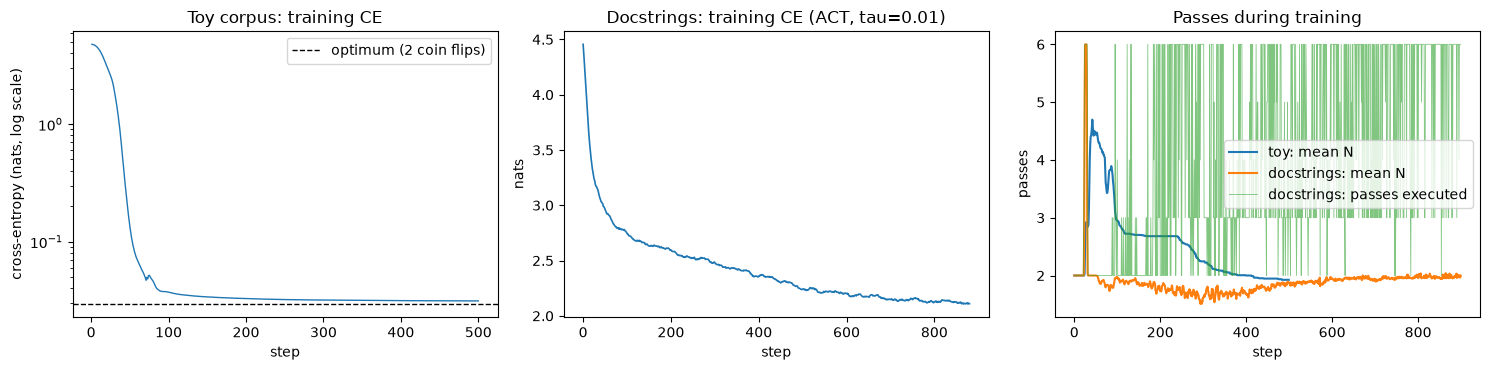

In [18]:
def smooth(values: list, k: int = 20) -> np.ndarray:
    v = np.asarray(values, dtype=float)
    return np.convolve(v, np.ones(k) / k, mode="valid")


fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
axes[0].plot(toy_hist["step"], toy_hist["loss"], lw=1)
axes[0].axhline(2 * math.log(2) / 47, color="k", ls="--", lw=1, label="optimum (2 coin flips)")
axes[0].set_yscale("log"); axes[0].set_title("Toy corpus: training CE"); axes[0].set_xlabel("step")
axes[0].set_ylabel("cross-entropy (nats, log scale)"); axes[0].legend()
axes[1].plot(smooth(act_hist["loss"]), lw=1.2)
axes[1].set_title("Docstrings: training CE (ACT, tau=0.01)"); axes[1].set_xlabel("step"); axes[1].set_ylabel("nats")
axes[2].plot(toy_hist["mean_N"], label="toy: mean N")
axes[2].plot(act_hist["mean_N"], label="docstrings: mean N")
axes[2].plot(act_hist["passes_run"], lw=0.6, alpha=0.6, label="docstrings: passes executed")
axes[2].set_title("Passes during training"); axes[2].set_xlabel("step"); axes[2].set_ylabel("passes"); axes[2].legend()
plt.tight_layout(); plt.show()

## 7. Look inside

### 7.1 Passes per character on the toy corpus

For each of the 4 sentences and each position we plot the ponder $N + R$ used to predict the **next** character. The two choice points are the predictions made at "the tiny |" (next is *m* or *r*) and "learned to |" (next is *w* or *s*).

after 'the tiny ': top-2 next chars [('r', 0.499), ('m', 0.498)], ponder [2.12 2.12 2.12 2.12]
after 'the tiny model learned to ': top-2 next chars [('s', 0.5), ('w', 0.497)], ponder [2.12 2.12 2.12 2.12]
toy model: mean N 1.93, ponder range [2.00, 2.31]
5 positions with the highest mean ponder: [(13, ' model', 2.29), (30, ' write', 2.28), (7, 'e tiny', 2.26), (26, 'd to w', 2.24), (35, 'e this', 2.22)]


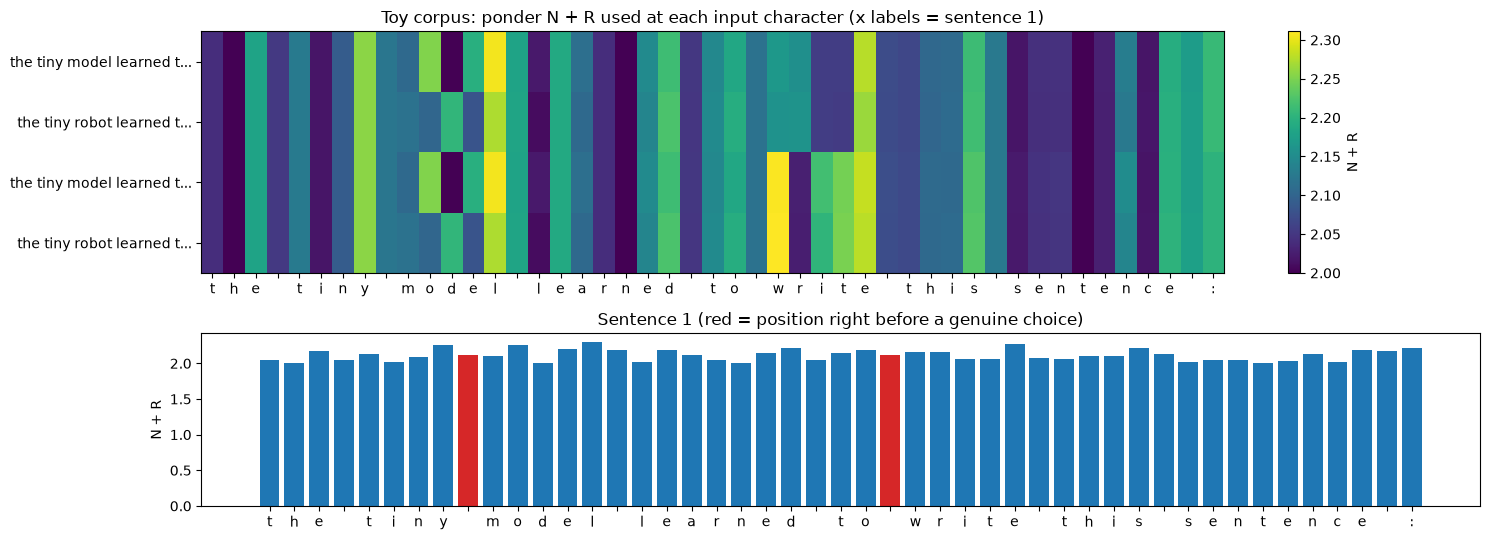

In [19]:
with torch.no_grad():
    toy_model.eval()
    toy_out = toy_model(TOY_X)
toy_ponder = toy_out["ponder"].numpy()          # (4, 47)
choice_positions = [TOY_CORPUS[0].index("model") - 1, TOY_CORPUS[0].index("write") - 1]  # input position BEFORE the choice
probs = F.softmax(toy_out["logits"], -1)
for pos in choice_positions:
    top = probs[0, pos].topk(2)
    print(f"after {TOY_CORPUS[0][:pos + 1]!r}: top-2 next chars "
          f"{[(tok.chars[int(i)], round(float(v), 3)) for v, i in zip(top.values, top.indices)]}, ponder {toy_ponder[:, pos].round(2)}")
print(f"toy model: mean N {toy_out['N'].mean():.2f}, ponder range [{toy_ponder.min():.2f}, {toy_ponder.max():.2f}]")
top_positions = np.argsort(-toy_ponder.mean(0))[:5]
print("5 positions with the highest mean ponder:",
      [(int(i), TOY_CORPUS[0][:int(i) + 1][-6:], round(float(toy_ponder[:, i].mean()), 2)) for i in top_positions])

fig, axes = plt.subplots(2, 1, figsize=(15, 5.5), gridspec_kw={"height_ratios": [1.4, 1]})
im = axes[0].imshow(toy_ponder, aspect="auto", cmap="viridis")
axes[0].set_yticks(range(4)); axes[0].set_yticklabels([s[:24] + "..." for s in TOY_CORPUS])
axes[0].set_xticks(range(47)); axes[0].set_xticklabels(list(TOY_CORPUS[0][:47]))
axes[0].set_title("Toy corpus: ponder N + R used at each input character (x labels = sentence 1)")
plt.colorbar(im, ax=axes[0], label="N + R")
colors = ["tab:red" if i in choice_positions else "tab:blue" for i in range(47)]
axes[1].bar(range(47), toy_ponder[0], color=colors)
axes[1].set_xticks(range(47)); axes[1].set_xticklabels(list(TOY_CORPUS[0][:47]))
axes[1].set_ylabel("N + R"); axes[1].set_title("Sentence 1 (red = position right before a genuine choice)")
plt.tight_layout(); plt.show()

### 7.2 Per-pass cumulative halting

For a few characters of one validation window we draw the cumulative halting mass $\sum_{t' \le t} p_{t'}$ against the pass number. A token halts at the first pass where its curve crosses the dashed $1 - \varepsilon$ line. The right panel shows the distribution of $N$ over the whole validation set.

window: ' is a little fancier than, an algorithm published in the late 19'


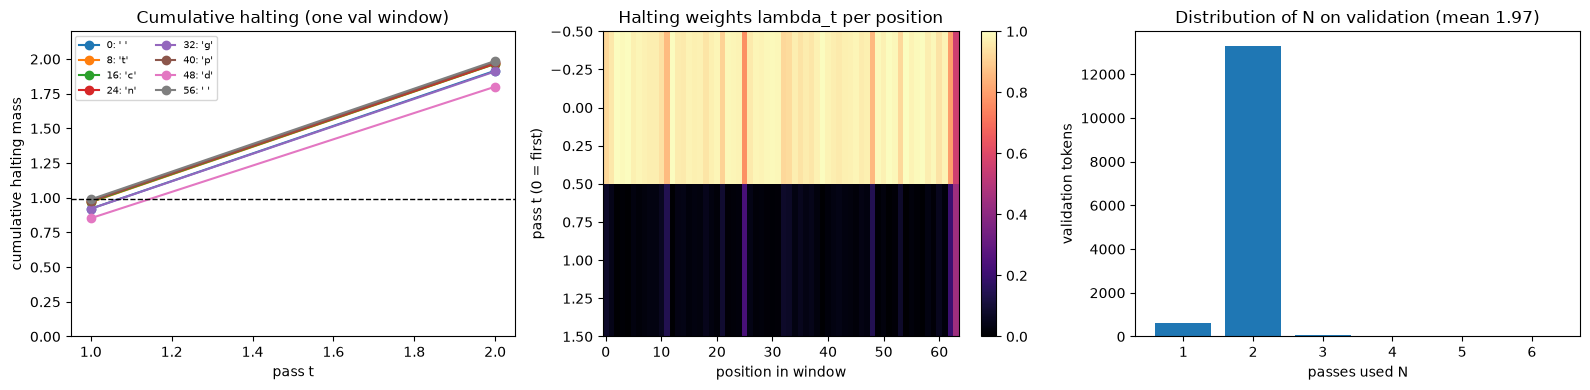

fraction of val tokens per N: {1: 0.044, 2: 0.949, 3: 0.004, 4: 0.0, 5: 0.0, 6: 0.003}


In [20]:
with torch.no_grad():
    act_model.eval()
    val_out = act_model(VAL_X[:1])
p_val = val_out["p"][:, 0].numpy()                      # (passes, L)
cum_val = np.cumsum(p_val, axis=0)
window_text = tok.decode(VAL_X[0])
print("window:", repr(window_text))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for pos in range(0, CONTEXT, 8):
    axes[0].plot(range(1, len(p_val) + 1), cum_val[:, pos], marker="o", label=f"{pos}: {window_text[pos]!r}")
axes[0].axhline(1 - act_model.eps, ls="--", color="k", lw=1)
axes[0].set_xlabel("pass t"); axes[0].set_ylabel("cumulative halting mass"); axes[0].set_ylim(0, 2.2)
axes[0].set_title("Cumulative halting (one val window)"); axes[0].legend(fontsize=7, ncol=2)
im = axes[1].imshow(val_out["weights"][:, 0].numpy(), aspect="auto", cmap="magma", vmin=0, vmax=1)
axes[1].set_xlabel("position in window"); axes[1].set_ylabel("pass t (0 = first)")
axes[1].set_title("Halting weights lambda_t per position"); plt.colorbar(im, ax=axes[1])
N_all = act_eval["N_tok"].flatten().numpy()
axes[2].hist(N_all, bins=np.arange(0.5, act_model.T_max + 1.5, 1), rwidth=0.8)
axes[2].set_xlabel("passes used N"); axes[2].set_ylabel("validation tokens")
axes[2].set_title(f"Distribution of N on validation (mean {N_all.mean():.2f})")
plt.tight_layout(); plt.show()
print("fraction of val tokens per N:", {int(n): round(float((N_all == n).mean()), 3) for n in np.unique(N_all)})

## 8. Experiments

### 8.1 The time penalty $\tau$: passes vs validation bits/char

Same model, same data order, same number of steps; only $\tau$ changes. The $\tau = 0.01$ run is the one from §6.2. We also add the fixed-depth baselines (`use_act=False`) with $T_{\max} = 6$ and with 2 passes, so we know what "always think 6 times" and "always think twice" cost.

In [21]:
TAUS = [0.0, 1e-3, 1e-2, 1e-1]
sweep = {}
for tau in TAUS:
    if tau == 1e-2:
        sweep[tau] = {"eval": act_eval, "hist": act_hist, "model": act_model}
        continue
    set_seed(0)
    model_tau = LoopedACT(tok.vocab_size, d_model=64, n_heads=4, T_max=6, halt_bias_init=1.0)
    hist_tau = train(model_tau, steps=DOC_STEPS, tau=tau, batch_fn=doc_batch, verbose=False)
    sweep[tau] = {"eval": evaluate(model_tau), "hist": hist_tau, "model": model_tau}
    print(f"tau={tau:g}: val {sweep[tau]['eval']['bpc']:.3f} bpc, mean N {sweep[tau]['eval']['mean_N']:.2f}, "
          f"{hist_tau['seconds']:.0f}s")

fixed = {}
for T_fixed in [2, 6]:
    set_seed(0)
    model_fixed = LoopedACT(tok.vocab_size, d_model=64, n_heads=4, T_max=T_fixed, use_act=False)
    hist_fixed = train(model_fixed, steps=DOC_STEPS, tau=0.0, batch_fn=doc_batch, verbose=False)
    fixed[T_fixed] = {"eval": evaluate(model_fixed), "hist": hist_fixed, "model": model_fixed}
    print(f"fixed T={T_fixed}: val {fixed[T_fixed]['eval']['bpc']:.3f} bpc, {hist_fixed['seconds']:.0f}s")

tau=0: val 3.549 bpc, mean N 2.11, 60s


tau=0.001: val 3.550 bpc, mean N 2.07, 39s


tau=0.1: val 3.570 bpc, mean N 1.23, 16s


fixed T=2: val 3.460 bpc, 14s


fixed T=6: val 3.408 bpc, 36s


model              val bits/char   mean N  mean N+R  passes run/step  ms/step   params
ACT tau=0                  3.549     2.11      2.36             6.00       66   67,299
ACT tau=0.001              3.550     2.07      2.27             5.96       43   67,299
ACT tau=0.01               3.550     1.97      2.10             5.20      119   67,299
ACT tau=0.1                3.570     1.23      2.01             2.13       18   67,299
fixed T=2                  3.460     2.00      2.00             2.00       15   66,978
fixed T=6                  3.408     6.00      6.00             6.00       40   67,234

shared block: 49,984 params; an unshared 6-layer stack would need 299,904 block params (model total 317,219)


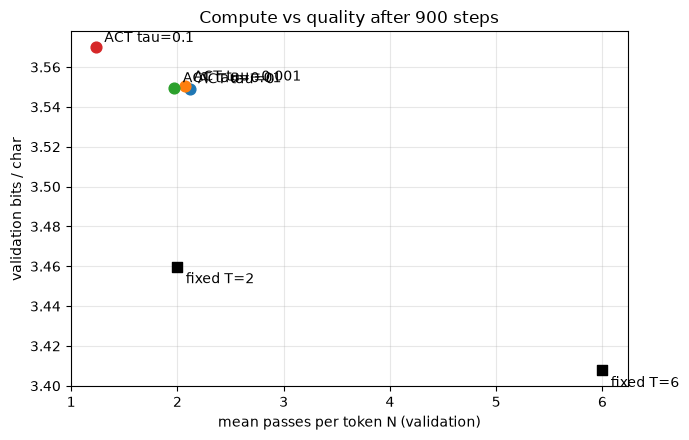

In [22]:
rows = []
print(f"{'model':<18}{'val bits/char':>14}{'mean N':>9}{'mean N+R':>10}{'passes run/step':>17}{'ms/step':>9}{'params':>9}")
for tau in TAUS:
    e, h = sweep[tau]["eval"], sweep[tau]["hist"]
    rows.append((f"ACT tau={tau:g}", e["bpc"], e["mean_N"], e["mean_ponder"], np.mean(h["passes_run"][-200:]),
                 1000 * h["seconds"] / DOC_STEPS))
for T_fixed in [2, 6]:
    e, h = fixed[T_fixed]["eval"], fixed[T_fixed]["hist"]
    rows.append((f"fixed T={T_fixed}", e["bpc"], float(T_fixed), float(T_fixed), float(T_fixed), 1000 * h["seconds"] / DOC_STEPS))
act_params = count_params(act_model)
for name, bpc, mN, mP, pr, ms in rows:
    # fixed-depth models own an (unused) 65-param halting unit; T=2 also has a smaller step embedding
    n_par = act_params if name.startswith("ACT") else count_params(fixed[int(name[-1])]["model"]) - 65
    print(f"{name:<18}{bpc:>14.3f}{mN:>9.2f}{mP:>10.2f}{pr:>17.2f}{ms:>9.0f}{n_par:>9,}")
unshared_block = count_params(fixed[6]["model"].block)
print(f"\nshared block: {unshared_block:,} params; an unshared 6-layer stack would need {6 * unshared_block:,} block params "
      f"(model total {count_params(fixed[6]['model']) + 5 * unshared_block:,})")

fig, ax = plt.subplots(figsize=(7, 4.5))
for tau in TAUS:
    e = sweep[tau]["eval"]
    ax.scatter(e["mean_N"], e["bpc"], s=60, zorder=3)
    ax.annotate(f"ACT tau={tau:g}", (e["mean_N"], e["bpc"]), textcoords="offset points", xytext=(6, 4))
for T_fixed in [2, 6]:
    e = fixed[T_fixed]["eval"]
    ax.scatter(T_fixed, e["bpc"], marker="s", color="k", s=60, zorder=3)
    ax.annotate(f"fixed T={T_fixed}", (T_fixed, e["bpc"]), textcoords="offset points", xytext=(6, -12))
ax.set_xlabel("mean passes per token N (validation)"); ax.set_ylabel("validation bits / char")
ax.set_title(f"Compute vs quality after {DOC_STEPS} steps"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

**What the sweep shows (numbers from this run):**

* **$\tau$ barely moves quality in the range 0 to 0.01.** Validation bits/char is 3.549 / 3.550 / 3.550 for $\tau$ = 0 / 0.001 / 0.01, and mean $N$ only drifts from 2.11 to 1.97. A large penalty $\tau = 0.1$ pushes mean $N$ down to 1.23 and costs just 0.02 bits/char (3.570). So the trade-off curve is **almost flat**: in this setting the ponder cost is *not* what keeps $N$ small. Even with $\tau = 0$ (no penalty at all) the model settles at about 2 passes.
* **Surprise: every ACT model is worse than the plain fixed-depth baselines.** Fixed $T=2$ reaches 3.460 and fixed $T=6$ reaches 3.408 bits/char, both with the same 900 steps and the same data. ACT with "mean $N \approx 2$" loses about 0.09 bits/char to a model that *always* runs 2 passes. The next cell explains why.
* **Nominal vs real compute.** "Passes run / step" counts how many times the dense loop actually executed. With $\tau = 0.01$ the average token uses $N = 1.97$, but the batch still ran **5.2 of 6 passes** on average, because a few slow tokens (0.3% of validation tokens use all 6 passes, see §7.2) keep the whole batch going. Only $\tau = 0.1$ brings real compute down (2.13 passes). The ms/step column is wall-clock time and depends on how busy the machine was (other jobs ran at the same time), so read it as a rough guide only. "Passes run" is the number that does not depend on load.
* **Parameters:** the ACT and fixed models have the same parameters except the 65-parameter halting unit. The looped model has about 67k parameters, while an unshared 6-layer stack would have about 317k.

**Where does the output actually come from?** "Mean $N \approx 2$" sounds like "two passes deep", but the output is the *mixture* $\sum_t \lambda_t h_t$. If most of the weight sits on pass 1, the head mostly sees a one-pass representation. We measure the average halting weight per pass on the validation set and the *effective depth* $\sum_t t\,\lambda_t$ (the average pass index the output is drawn from).

In [23]:
print(f"{'ACT model':<12}" + "".join(f"{'mean lam_' + str(t + 1):>11}" for t in range(6)) + f"{'eff. depth':>12}{'mean p_1':>10}")
for tau in TAUS:
    mdl = sweep[tau]["model"]
    mdl.eval()
    lam = torch.zeros(6)
    p1 = []
    with torch.no_grad():
        for i in range(0, len(VAL_X), 64):
            o = mdl(VAL_X[i:i + 64])
            lam[:o["weights"].shape[0]] += o["weights"].sum(dim=(1, 2))   # sum lambda_t over all tokens
            p1.append(o["p"][0].flatten())
    mdl.train()
    lam = lam / VAL_X.numel()
    assert abs(lam.sum().item() - 1.0) < 1e-4, "average halting weights must still sum to 1"
    eff_depth = (torch.arange(1, 7) * lam).sum().item()
    sweep[tau]["eff_depth"] = eff_depth
    print(f"tau={tau:<8g}" + "".join(f"{v:>11.3f}" for v in lam.tolist()) + f"{eff_depth:>12.2f}{torch.cat(p1).mean():>10.3f}")

ACT model    mean lam_1 mean lam_2 mean lam_3 mean lam_4 mean lam_5 mean lam_6  eff. depth  mean p_1
tau=0             0.722      0.261      0.012      0.002      0.001      0.003        1.31     0.722


tau=0.001         0.777      0.212      0.008      0.001      0.000      0.002        1.24     0.777
tau=0.01          0.916      0.082      0.001      0.000      0.000      0.001        1.09     0.916
tau=0.1           0.992      0.008      0.000      0.000      0.000      0.000        1.01     0.990


**This explains the surprise.** With $\tau = 0.01$, **91.6% of the output weight comes from pass 1**: the mean of $p_1$ is 0.916 and the effective depth is only **1.09**. The model learned to put almost all of its mass on the first pass. Because $0.916 < 1 - \varepsilon = 0.99$, the halting rule still forces a second pass, but that pass only receives the small remainder $R \approx 0.08$. So "mean $N = 2$" is mostly bookkeeping. **In practice the ACT model is a ~1-pass model that pays for 2 passes (and, because of the batch-level loop, for ~5).** Even without any penalty ($\tau = 0$) the effective depth is only 1.31. The fixed $T=2$ model really uses its second pass, which is why it wins.

Why does training settle there? The task gradient on $p_1$ is $\partial y / \partial p_1 = h_1 - h_N$ (§3.4). Early in training $h_1$ is about as useful as $h_2$, so nothing pushes $p_1$ down, while the ponder term ($\tau > 0$) always pushes it up. This is a known weakness of ACT: it is sensitive to $\tau$ and to initialisation, and it tends toward shallow, nearly uniform halting. That is part of the motivation for PonderNet (arXiv:2107.05407), which samples the halting step and regularises it toward a geometric prior instead. Our runs are short (900 steps), so a longer run *might* behave differently. We did not test that here.

### 8.2 Halting bias initialisation and early training

The halting weight $w$ starts at zero, so at step 0 **every** token has $p = \sigma(b)$ on every pass and halts at the same $N$:

| $b$ | $p=\sigma(b)$ | initial $N$ |
|---|---|---|
| -3 | 0.047 | 6 (never reaches 0.99 → forced at $T_{\max}$) |
| 0 | 0.5 | 2 |
| 1 | 0.731 | 2 |
| 5 | 0.993 | 1 |

We train 300 steps with each $b$ ($\tau = 0.01$) and look at the training loss and mean $N$.

bias -3: initial N 6.00 | after 300 steps: train CE (last 50) 2.587, val 4.049 bpc, mean N 2.55, 12s


bias +0: initial N 2.00 | after 300 steps: train CE (last 50) 2.602, val 4.062 bpc, mean N 2.00, 7s


bias +1: initial N 2.00 | after 300 steps: train CE (last 50) 2.603, val 4.064 bpc, mean N 1.96, 6s


bias +5: initial N 1.00 | after 300 steps: train CE (last 50) 2.609, val 4.070 bpc, mean N 1.00, 3s


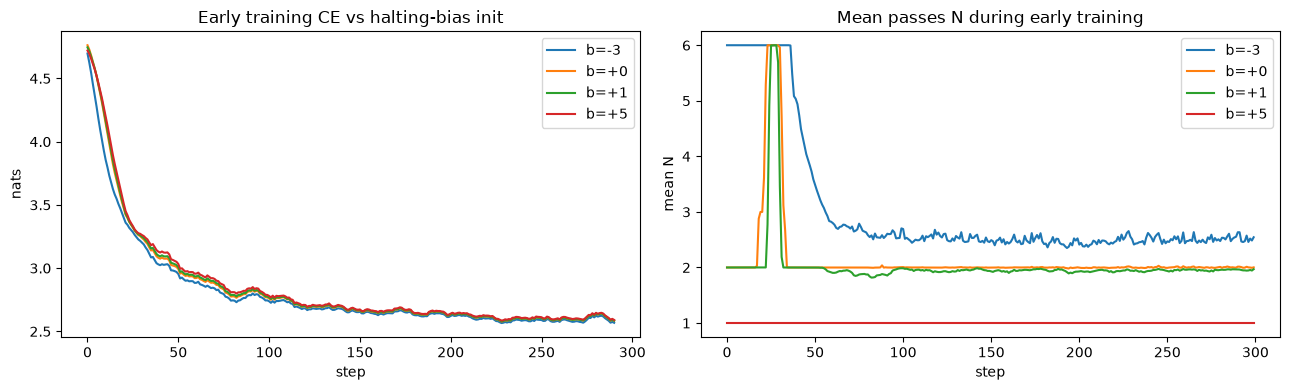

In [24]:
BIAS_STEPS = 300
bias_runs = {}
for bias in [-3.0, 0.0, 1.0, 5.0]:
    set_seed(0)
    model_b = LoopedACT(tok.vocab_size, d_model=64, n_heads=4, T_max=6, halt_bias_init=bias)
    with torch.no_grad():
        N0 = model_b(VAL_X[:8])["N"].mean().item()
    hist_b = train(model_b, steps=BIAS_STEPS, tau=0.01, batch_fn=doc_batch, verbose=False)
    bias_runs[bias] = {"hist": hist_b, "eval": evaluate(model_b), "N0": N0}
    print(f"bias {bias:+.0f}: initial N {N0:.2f} | after {BIAS_STEPS} steps: train CE (last 50) "
          f"{np.mean(hist_b['loss'][-50:]):.3f}, val {bias_runs[bias]['eval']['bpc']:.3f} bpc, "
          f"mean N {bias_runs[bias]['eval']['mean_N']:.2f}, {hist_b['seconds']:.0f}s")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for bias, r in bias_runs.items():
    axes[0].plot(smooth(r["hist"]["loss"], 10), label=f"b={bias:+.0f}")
    axes[1].plot(r["hist"]["mean_N"], label=f"b={bias:+.0f}")
axes[0].set_title("Early training CE vs halting-bias init"); axes[0].set_xlabel("step"); axes[0].set_ylabel("nats"); axes[0].legend()
axes[1].set_title("Mean passes N during early training"); axes[1].set_xlabel("step"); axes[1].set_ylabel("mean N"); axes[1].legend()
plt.tight_layout(); plt.show()

**Halting bias: small effect on quality, large effect on early compute.** After 300 steps the validation bits/char are 4.049 / 4.062 / 4.064 / 4.070 for $b$ = -3 / 0 / +1 / +5. The ordering is "more initial thinking is slightly better", but the whole spread is only 0.02 bits/char. The compute cost differs much more: $b = -3$ starts with every token using all 6 passes, falls to mean $N = 2.55$ by step 300, and took the longest wall-clock time of the four runs. $b = +5$ starts at $N = 1$ and **stays exactly at 1**. With $p \approx 0.993$ every token halts on pass 1 with $R = 1$, so the ponder gradient is zero (token B in §3.4). The task gradient through $y$ is also zero, because there is only one state to mix. So nothing can change the halting decision. **Never initialise the halting bias so high that tokens halt on pass 1: ACT can never learn to think longer from there.** Values around 0 to 1 (the Universal Transformer code uses 1.0) give $N = 2$ at the start, which keeps a useful gradient on $p_1$.

### 8.3 Does ACT spend more passes on harder characters?

"Hard" needs a definition that does not come from the ACT model itself. We use the **per-character validation loss of the fixed-depth $T=6$ model** from §8.1: a character it predicts badly is hard. Then we correlate that with the ponder $N + R$ that the ACT model ($\tau = 0.01$) chose for the same character, over all 14,016 validation predictions (219 windows × 64). We report Pearson and Spearman (rank) correlation, and break the numbers down by the kind of character being predicted.

ACT model      std(N+R)  Pearson(hard, N+R)  Spearman(hard, N+R)  Spearman(own loss, N+R)
tau=0             0.529               0.192                0.227                    0.230
tau=0.001         0.434               0.172                0.202                    0.204
tau=0.01          0.255               0.098                0.038                    0.036
tau=0.1           0.028               0.060               -0.014                   -0.020

target type             share  fixed-T6 loss (nats)  ACT tau=0.01 N+R
space                    0.15                 0.799             2.115
1st letter of word       0.13                 3.286             2.092
letter inside word       0.60                 2.230             2.062
digit / punctuation      0.11                 4.121             2.265


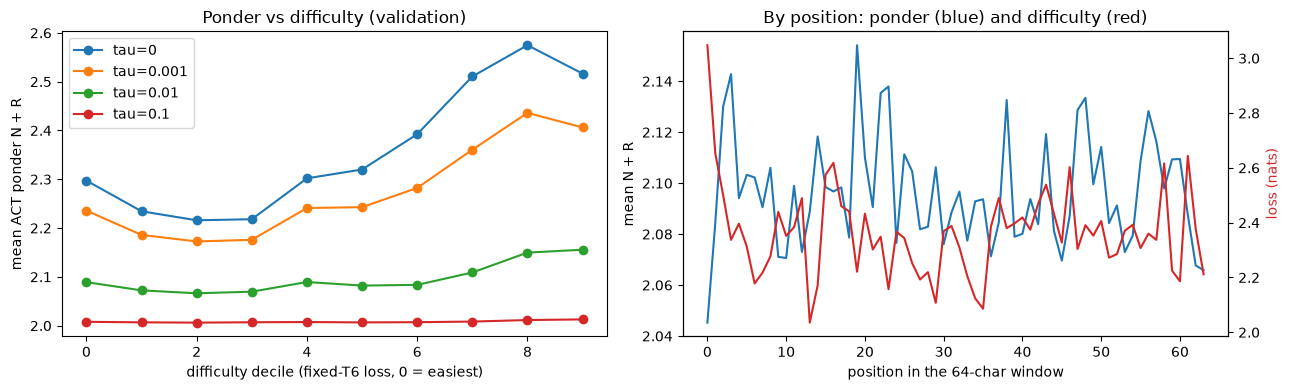

In [25]:
def spearman(a: np.ndarray, b: np.ndarray) -> float:
    """Rank correlation: Pearson correlation of the ranks (ties broken arbitrarily, fine for a large sample)."""
    ra = np.argsort(np.argsort(a)).astype(float)
    rb = np.argsort(np.argsort(b)).astype(float)
    return float(np.corrcoef(ra, rb)[0, 1])


hard = fixed[6]["eval"]["loss_tok"].flatten().numpy()        # difficulty = fixed-T loss
corr_rows = []
for tau in TAUS:
    pond = sweep[tau]["eval"]["ponder_tok"].flatten().numpy()
    own_loss = sweep[tau]["eval"]["loss_tok"].flatten().numpy()
    if pond.std() < 1e-6:
        corr_rows.append((tau, pond.std(), float("nan"), float("nan"), float("nan")))
        continue
    corr_rows.append((tau, pond.std(), float(np.corrcoef(hard, pond)[0, 1]), spearman(hard, pond), spearman(own_loss, pond)))
print(f"{'ACT model':<14}{'std(N+R)':>9}{'Pearson(hard, N+R)':>20}{'Spearman(hard, N+R)':>21}{'Spearman(own loss, N+R)':>25}")
for tau, sd, pr, sr, so in corr_rows:
    print(f"tau={tau:<10g}{sd:>9.3f}{pr:>20.3f}{sr:>21.3f}{so:>25.3f}")

# Break down by the kind of character being predicted (the TARGET).
targets = VAL_Y.flatten().numpy()
prev = VAL_X.flatten().numpy()
space_id = tok.stoi[" "]
target_chars = np.array([tok.chars[i] for i in targets])
is_letter = np.char.isalpha(target_chars)
groups = {
    "space": targets == space_id,
    "1st letter of word": is_letter & (prev == space_id),
    "letter inside word": is_letter & (prev != space_id),
    "digit / punctuation": ~is_letter & (targets != space_id),
}
pond = sweep[1e-2]["eval"]["ponder_tok"].flatten().numpy()
print(f"\n{'target type':<22}{'share':>7}{'fixed-T6 loss (nats)':>22}{'ACT tau=0.01 N+R':>18}")
for g, mask in groups.items():
    print(f"{g:<22}{mask.mean():>7.2f}{hard[mask].mean():>22.3f}{pond[mask].mean():>18.3f}")

# Binned plot: mean ponder for each decile of difficulty.
deciles = np.quantile(hard, np.linspace(0, 1, 11))
bin_id = np.clip(np.digitize(hard, deciles[1:-1]), 0, 9)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for tau in TAUS:
    p_tau = sweep[tau]["eval"]["ponder_tok"].flatten().numpy()
    axes[0].plot(range(10), [p_tau[bin_id == k].mean() for k in range(10)], marker="o", label=f"tau={tau:g}")
axes[0].set_xlabel("difficulty decile (fixed-T6 loss, 0 = easiest)"); axes[0].set_ylabel("mean ACT ponder N + R")
axes[0].set_title("Ponder vs difficulty (validation)"); axes[0].legend()
pos_mean = sweep[1e-2]["eval"]["ponder_tok"].mean(0).numpy()
axes[1].plot(pos_mean, label="ACT tau=0.01: mean N+R")
ax2 = axes[1].twinx()
ax2.plot(fixed[6]["eval"]["loss_tok"].mean(0).numpy(), color="tab:red", label="fixed-T6 loss")
axes[1].set_xlabel("position in the 64-char window"); axes[1].set_ylabel("mean N + R"); ax2.set_ylabel("loss (nats)", color="tab:red")
axes[1].set_title("By position: ponder (blue) and difficulty (red)")
plt.tight_layout(); plt.show()

**Honest answer: only weakly, and less as $\tau$ grows.**

* With $\tau = 0$ the ponder correlates mildly with difficulty: Spearman **0.23** against the fixed-$T$ loss, Pearson 0.19. Raising $\tau$ shrinks both the variation in ponder (std of $N+R$: 0.53 → 0.43 → 0.26 → 0.03) and the correlation (Spearman 0.20 at $\tau = 10^{-3}$, **0.04** at $\tau = 10^{-2}$, about 0 at $\tau = 0.1$). The model we trained as the "main" one ($\tau = 0.01$) has almost no relationship between ponder and difficulty.
* By character type, the hardest targets (digits/punctuation, 4.12 nats under the fixed model) do get the most ponder (2.27 vs 2.06-2.12). But the second-hardest type, the **first letter of a word** (3.29 nats), gets *less* ponder (2.09) than **spaces** (2.12), which are the easiest (0.80 nats). ACT's allocation is not "hard → more thinking" in any clean way.
* On the toy corpus (§7.1) the genuine choice points get *no extra* ponder (2.12, the same as most positions). That makes sense: a 50/50 choice between *model* and *robot* is irreducible uncertainty, and no amount of extra computation can resolve it. The slightly higher values (about 2.25-2.29) sit just after the chosen words (*model|*, *write|*).

This matches a common finding: ACT's per-token compute is only loosely tied to difficulty, and small models trained briefly tend to use nearly uniform depth.

## 9. Common pitfalls & debugging tips

Every item below is something that showed up while building and running this notebook.

1. **"Mean $N$" can lie.** Our main model reports $N \approx 2$, but 92% of its output comes from pass 1 (effective depth 1.09). Always log the halting weights $\lambda_t$ or $\sum_t t\lambda_t$, not just $N$.
2. **Per-token savings are not wall-clock savings.** In a dense batch the loop runs until the *slowest* token halts. 0.3% of tokens using 6 passes kept the batch running 5.2 of 6 passes. Real savings need gathering the still-running tokens, or token-level kernels.
3. **Halting bias too high = ACT is dead.** With $b = 5$ every token halts on pass 1 and both gradients on $p$ are exactly zero, so $N$ stayed at 1.00 for the whole run.
4. **$N$ has no gradient.** If you write the ponder cost as $N$ alone, it is a constant to autograd and $\tau$ does nothing. The gradient comes from $R$. Check with `requires_grad` as in §3.4.
5. **Off-by-one in the remainder.** $R$ uses the sum of $p$ over the passes *before* the halting pass (an exclusive cumsum). We caught this kind of bug by implementing the rule twice (incremental loop vs `cumsum`) and asserting they agree on random inputs.
6. **Remember the forced halt at $T_{\max}$.** Tokens that never cross $1-\varepsilon$ must still get weight $R$ on the last pass, or their weights will not sum to 1 (token C in §3.3). Assert $\sum_t \lambda_t = 1$.
7. **Causality with early exit.** Breaking out of the loop when the whole batch has halted makes the *number of passes* depend on future tokens. It is safe only because halted outputs are frozen (weight 0). If you change the design, for example by copying states, re-run the perturbation test of §4.
8. **`.numpy()` on a tensor that requires grad** fails. Wrap analysis code in `torch.no_grad()` (we hit this error while writing §4).
9. **Timing is noisy on a shared machine.** Wall-clock ms/step varied between our runs because other jobs were running. Count passes, not seconds, when you compare compute.

## 10. Recap

* A looped transformer reuses **one** block for up to $T_{\max}$ passes. ACT adds a 65-parameter halting unit so that each token chooses its own number of passes $N$.
* The bookkeeping is: accumulate $p_t$ until the sum reaches $1-\varepsilon$, give the last pass the remainder $R$, and output the $\lambda$-weighted mixture of states. The ponder cost is $\tau \cdot \mathrm{mean}(N + R)$. Only $R$ carries gradient.
* Halted tokens keep being transformed (others can attend to them) but their output is frozen. This keeps the model causal even with batch-level early exit.
* **Measured here:** on 143k characters of docstrings, ACT ($\tau = 0.01$) reached 3.550 bits/char with mean $N = 1.97$ but an effective depth of only 1.09. The fixed 2-pass and 6-pass looped models reached 3.460 and 3.408. $\tau$ in [0, 0.01] barely changed anything. ACT's ponder correlated only weakly with character difficulty (Spearman 0.23 at $\tau = 0$, 0.04 at $\tau = 0.01$).

**Cheat sheet**

| quantity | formula | shape | gradient? |
|---|---|---|---|
| halting prob | $p_t = \sigma(w^\top h_t + b)$ | (B, L) | yes |
| passes used | $N = \min\{n : \sum_{t \le n} p_t \ge 1-\varepsilon\}$, capped at $T_{\max}$ | (B, L), integer | **no** |
| remainder | $R = 1 - \sum_{t<N} p_t$ | (B, L) | yes, $\partial R/\partial p_{t<N} = -1$ |
| weights | $\lambda_t = p_t\ (t<N),\ R\ (t=N),\ 0\ (t>N)$, $\sum_t \lambda_t = 1$ | (T, B, L) | yes |
| output | $y = \sum_t \lambda_t h_t$ | (B, L, d) | yes |
| loss | $\mathrm{CE} + \tau \cdot \mathrm{mean}(N+R)$ | scalar | |
| good habits | log effective depth $\sum_t t\lambda_t$, count executed passes, init $b \in [0, 1]$, never $b \gtrsim 4.6$ | | |

**Exercises**

1. *Copy instead of transform.* Change `LoopedACT` so that halted tokens' **states** stop changing (`h = torch.where(running, h_new, h_old)`), as in some ACT implementations. Does the causality test still pass? Does validation bits/char change? *Hint:* only the `forward` loop needs editing; keep the frozen-output assert.
2. *PonderNet-style halting.* Replace the deterministic mixture with the PonderNet objective: $\lambda_t = p_t \prod_{s<t}(1-p_s)$, loss $= \sum_t \lambda_t \mathrm{CE}_t + \beta\,\mathrm{KL}(\lambda \,\|\, \mathrm{Geometric}(\lambda_p))$. Does the effective depth rise above 1.09? *Hint:* you need the per-pass logits, so apply `ln_f` + `head` to every $h_t$.
3. *Gather the running tokens.* Make the per-token savings real: on each pass, run the block only on the positions that are still running (the halted ones are still needed as keys/values). Measure wall-clock vs fixed $T=2$. *Hint:* the queries shrink, but the keys/values must still cover the whole sequence; use attention with separate `query` and `key`/`value` inputs.

**References**

* A. Graves, *Adaptive Computation Time for Recurrent Neural Networks*, arXiv:1603.08983 (2016).
* M. Dehghani, S. Gouws, O. Vinyals, J. Uszkoreit, Ł. Kaiser, *Universal Transformers*, arXiv:1807.03819 (2018).
* A. Banino, J. Balaguer, C. Blundell, *PonderNet: Learning to Ponder*, arXiv:2107.05407 (2021). A probabilistic alternative to ACT's halting.

In [26]:
print(f"total notebook runtime: {(time.time() - NOTEBOOK_START) / 60:.1f} min")

total notebook runtime: 5.4 min
